<a href="https://colab.research.google.com/github/fatasa/Tesis/blob/main/baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import cv2
from time import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pandas import DataFrame

from google.colab import drive
import gc
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, classification_report

#mount Google Drive
drive.mount('/content/drive')

#menjaga reproduksibilitas
np.random.seed(42)
tf.random.set_seed(42)

DATASET_DRIVE_PATH = '/content/drive/MyDrive/cell_images'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
#PREPROCESSING
def load_and_preprocess_dataset(dataset_dir, input_size=(64, 64)):
    images = []
    labels = []
    categories = ['Uninfected', 'Parasitized'] # 0: Uninfected, 1: Parasitized

    for category in categories:
        folder_path = os.path.join(dataset_dir, category)
        label = 0 if category == 'Uninfected' else 1

        if not os.path.exists(folder_path):
            print(f"Warning: Folder {folder_path} tidak ditemukan.")
            continue

        print(f"---> Memuat data dari folder: {category}...")
        for img_name in os.listdir(folder_path):
            img_path = os.path.join(folder_path, img_name)
            if img_path.lower().endswith(('.png', '.jpg', '.jpeg')):
                img = cv2.imread(img_path)
                if img is not None:
                    # Konversi BGR (default OpenCV) ke RGB
                    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                    # 1. Resize Spasial (Skenario 1: 64x64)
                    img = cv2.resize(img, input_size)
                    # 2. Normalisasi Pixel Scaling
                    img = img.astype('float32') / 255.0

                    images.append(img)
                    labels.append(label)

    X = np.array(images, dtype='float32')
    y = np.array(labels, dtype='float32')
    print(f"Total dataset asli berhasil dimuat & dipreprocess: {X.shape[0]} citra | Shape: {X.shape}")
    return X, y

In [3]:
#BASE-LEARNER CUSTOM CNN
#CNN 1 (3 Layer)
def build_cnn_1(input_shape=(64, 64, 3)):
    model = models.Sequential([
        # Layer Konvolusi 1 (16 Filter)
        layers.Conv2D(16, (3, 3), strides=1, padding='same', activation='relu', input_shape=input_shape),
        layers.MaxPooling2D((2, 2)),

        # Layer Konvolusi 2 (32 Filter)
        layers.Conv2D(32, (3, 3), strides=1, padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Layer Konvolusi 3 (64 Filter)
        layers.Conv2D(64, (3, 3), strides=1, padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Fully Connected Layer
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(1, activation='sigmoid') #Probabilitas Output Sigmoid
    ], name="CNN_1")
    return model

#CNN 2 (4 Layer)
def build_cnn_2(input_shape=(64, 64, 3)):
    model = models.Sequential([
        # Layer Konvolusi 1 (16 Filter)
        layers.Conv2D(16, (3, 3), strides=1, padding='same', activation='relu', input_shape=input_shape),
        layers.MaxPooling2D((2, 2)),

        # Layer Konvolusi 2 (32 Filter)
        layers.Conv2D(32, (3, 3), strides=1, padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Layer Konvolusi 3 (64 Filter)
        layers.Conv2D(64, (3, 3), strides=1, padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Layer Konvolusi 4 (128 Filter)
        layers.Conv2D(128, (3, 3), strides=1, padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Fully Connected Layer
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(1, activation='sigmoid')
    ], name="CNN_2")
    return model

#CNN 3 (5 Layer)
def build_cnn_3(input_shape=(64, 64, 3)):
    model = models.Sequential([
        # Layer Konvolusi 1 (16 Filter)
        layers.Conv2D(16, (3, 3), strides=1, padding='same', activation='relu', input_shape=input_shape),
        layers.MaxPooling2D((2, 2)),

        # Layer Konvolusi 2 (32 Filter)
        layers.Conv2D(32, (3, 3), strides=1, padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Layer Konvolusi 3 (64 Filter)
        layers.Conv2D(64, (3, 3), strides=1, padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Layer Konvolusi 4 (128 Filter)
        layers.Conv2D(128, (3, 3), strides=1, padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Layer Konvolusi 5 (256 Filter)
        layers.Conv2D(256, (3, 3), strides=1, padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Fully Connected Layer
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(1, activation='sigmoid')
    ], name="CNN_3")
    return model

In [4]:
#SIGMOID AVERAGE
def sigmoid_average(cnn1, cnn2, cnn3, X_data):
    # 1. Prediksi probabilitas P(Parasitized) dari masing-masing model
    p1 = cnn1.predict(X_data, batch_size=32, verbose=0) # Output CNN 1
    p2 = cnn2.predict(X_data, batch_size=32, verbose=0) # Output CNN 2
    p3 = cnn3.predict(X_data, batch_size=32, verbose=0) # Output CNN 3

    # 2. Hitung Rata-rata Probabilitas
    avg_p_parasitized = (p1 + p2 + p3) / 3.0          # \bar{h}_1 (Kelas Parasitized)
    avg_p_uninfected = 1.0 - avg_p_parasitized        # \bar{h}_0 (Kelas Uninfected)

    # 3. Gabungkan menjadi Vektor Input Meta-Learner (N, 2)
    meta_features = np.hstack((avg_p_uninfected, avg_p_parasitized))
    return meta_features

In [5]:
#META-LEARNER MLP
def build_mlp(hidden_units=(64, 32)):
    model = models.Sequential([
        layers.Input(shape=(2,)),                          # Input Layer: [\bar{h}_0, \bar{h}_1]
        layers.Dense(hidden_units[0], activation='relu'), # Hidden Layer 1
        layers.Dense(hidden_units[1], activation='relu'), # Hidden Layer 2
        layers.Dropout(0.5),                               # Regulasi Dropout 0.5
        layers.Dense(1, activation='sigmoid')             # Output Layer
    ], name=f"MLP_{hidden_units[0]}_{hidden_units[1]}")

    model.compile(optimizer=optimizers.Adam(learning_rate=1e-3),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model

In [6]:
def plot_training_history(history, model_name="Model"):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 4.5))

    # Grafik Akurasi
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy', color='blue', linewidth=2)
    plt.plot(epochs_range, val_acc, label='Validation Accuracy', color='orange', linestyle='--', linewidth=2)
    plt.title(f'Accuracy Curve - {model_name}', fontsize=12, fontweight='bold')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')
    plt.grid(True, linestyle=':', alpha=0.6)

    # Grafik Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss', color='blue', linewidth=2)
    plt.plot(epochs_range, val_loss, label='Validation Loss', color='orange', linestyle='--', linewidth=2)
    plt.title(f'Loss Curve - {model_name}', fontsize=12, fontweight='bold')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')
    plt.grid(True, linestyle=':', alpha=0.6)

    plt.tight_layout()
    plt.show()

---> Memuat data dari folder: Uninfected...
---> Memuat data dari folder: Parasitized...
Total dataset asli berhasil dimuat & dipreprocess: 27558 citra | Shape: (27558, 64, 64, 3)

---> Pembagian Data
Data Latih: 22046 citra | Data Uji: 5512 citra


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



[Melatih Model Base-Learner CNN 1/3: CNN_1]
Epoch 1/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 25s 22ms/step - accuracy: 0.8368 - loss: 0.3504 - val_accuracy: 0.9550 - val_loss: 0.1487
Epoch 2/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9515 - loss: 0.1612 - val_accuracy: 0.9556 - val_loss: 0.1359
Epoch 3/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9553 - loss: 0.1435 - val_accuracy: 0.9556 - val_loss: 0.1326
Epoch 4/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9576 - loss: 0.1344 - val_accuracy: 0.9548 - val_loss: 0.1355
Epoch 5/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9586 - loss: 0.1210 - val_accuracy: 0.9561 - val_loss: 0.1283
Epoch 6/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9616 - loss: 0.1146 - val_accuracy: 0.9565 - val_loss: 0.1298
Epoch 7/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9628 - loss: 0.1087 - val_accuracy: 0.9548 - val_loss: 0.1287
Epoch 8/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc

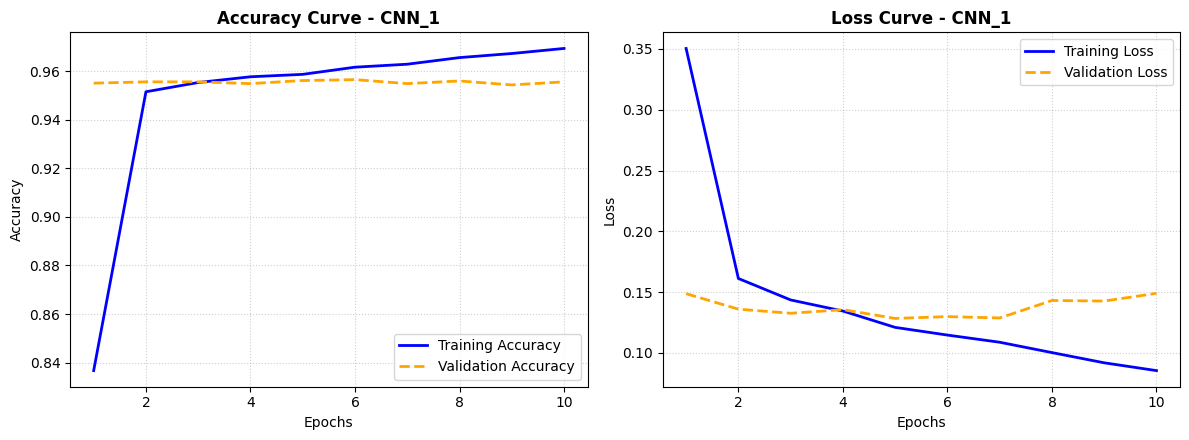


[Melatih Model Base-Learner CNN 2/3: CNN_2]
Epoch 1/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 18s 16ms/step - accuracy: 0.8566 - loss: 0.3068 - val_accuracy: 0.9545 - val_loss: 0.1452
Epoch 2/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9544 - loss: 0.1506 - val_accuracy: 0.9572 - val_loss: 0.1319
Epoch 3/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9582 - loss: 0.1344 - val_accuracy: 0.9568 - val_loss: 0.1314
Epoch 4/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9603 - loss: 0.1249 - val_accuracy: 0.9588 - val_loss: 0.1238
Epoch 5/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9615 - loss: 0.1162 - val_accuracy: 0.9581 - val_loss: 0.1253
Epoch 6/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9643 - loss: 0.1078 - val_accuracy: 0.9561 - val_loss: 0.1326
Epoch 7/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9657 - loss: 0.1019 - val_accuracy: 0.9565 - val_loss: 0.1421
Epoch 8/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - acc

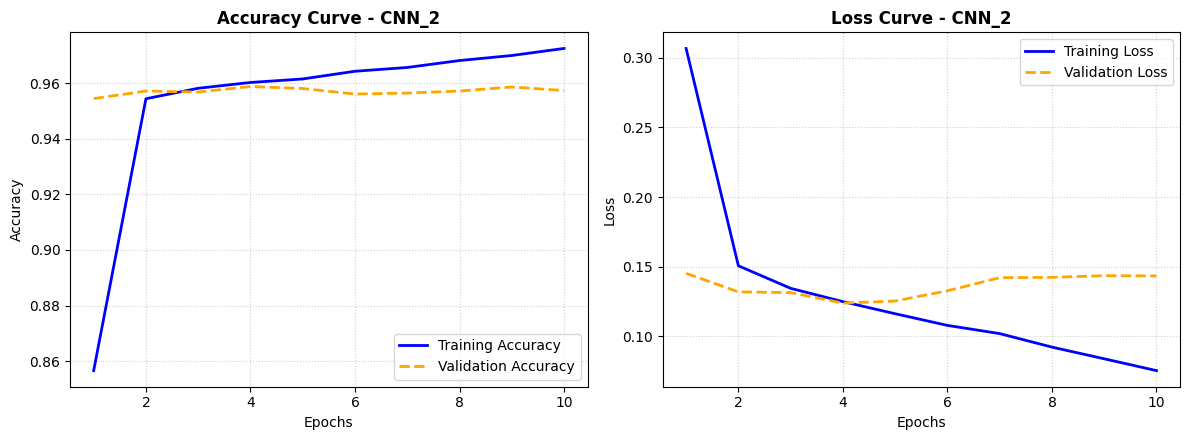


[Melatih Model Base-Learner CNN 3/3: CNN_3]
Epoch 1/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 19s 18ms/step - accuracy: 0.7726 - loss: 0.4254 - val_accuracy: 0.9519 - val_loss: 0.1480
Epoch 2/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9554 - loss: 0.1545 - val_accuracy: 0.9583 - val_loss: 0.1325
Epoch 3/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9594 - loss: 0.1342 - val_accuracy: 0.9610 - val_loss: 0.1227
Epoch 4/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9609 - loss: 0.1211 - val_accuracy: 0.9608 - val_loss: 0.1191
Epoch 5/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9649 - loss: 0.1101 - val_accuracy: 0.9606 - val_loss: 0.1187
Epoch 6/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9664 - loss: 0.0996 - val_accuracy: 0.9601 - val_loss: 0.1195
Epoch 7/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9707 - loss: 0.0891 - val_accuracy: 0.9615 - val_loss: 0.1228
Epoch 8/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - acc

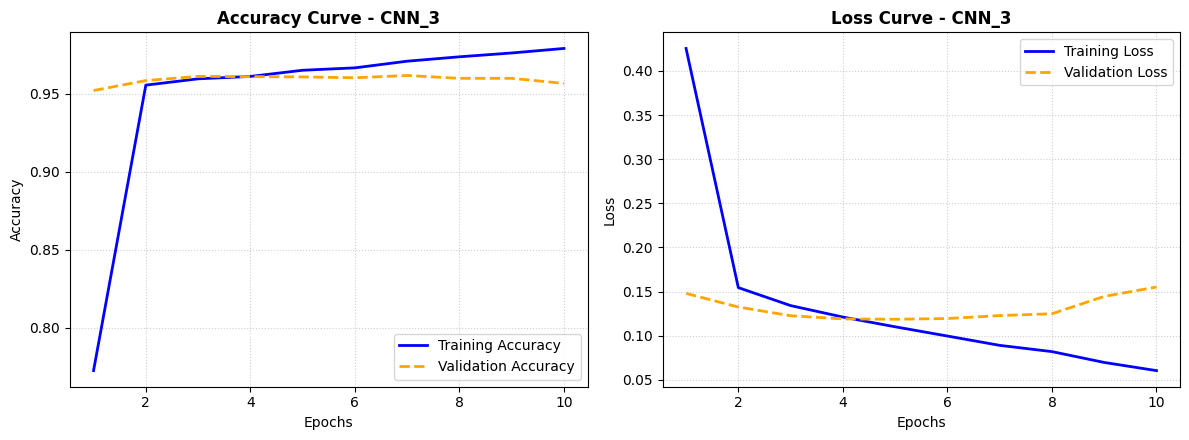


---> Sigmoid Average
Shape Meta-Features Data Latih : (22046, 2)
Shape Meta-Features Data Uji   : (5512, 2)

[Melatih Model Meta-Learner MLP]
Epoch 1/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9644 - loss: 0.1703 - val_accuracy: 0.9592 - val_loss: 0.1654
Epoch 2/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9771 - loss: 0.0960 - val_accuracy: 0.9599 - val_loss: 0.1631
Epoch 3/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9780 - loss: 0.0905 - val_accuracy: 0.9594 - val_loss: 0.1620
Epoch 4/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9779 - loss: 0.0856 - val_accuracy: 0.9588 - val_loss: 0.1609
Epoch 5/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9778 - loss: 0.0804 - val_accuracy: 0.9590 - val_loss: 0.1578
Epoch 6/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9773 - loss: 0.0783 - val_accuracy: 0.9586 - val_loss: 0.1609
Epoch 7/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9774 - loss: 0.0765 - v

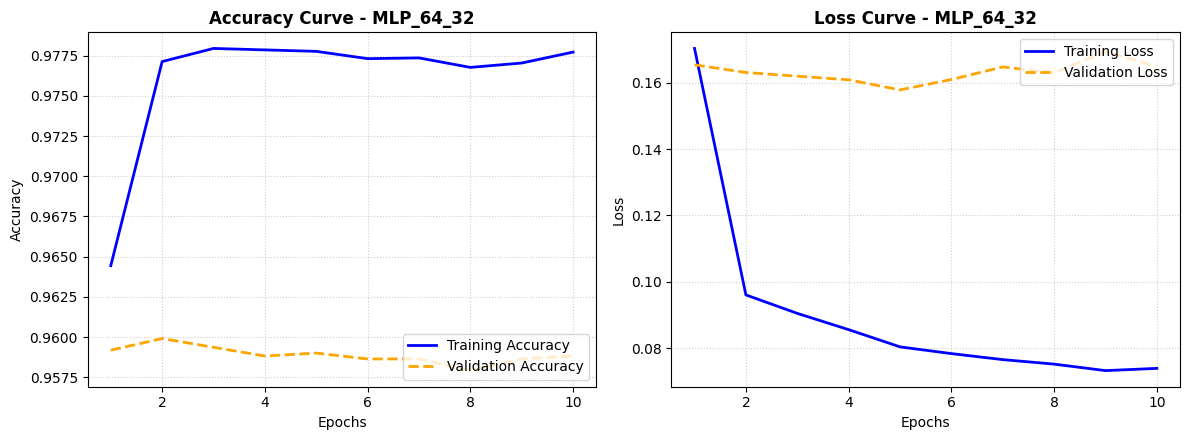


PELATIHAN MODEL SELESAI!


In [7]:
#RUN MODEL
if os.path.exists(DATASET_DRIVE_PATH):
    # 1. Preprocessing Dataset Asli (Resize 1: 64x64 & Normalisasi)
    X, y = load_and_preprocess_dataset(DATASET_DRIVE_PATH, input_size=(64, 64))

    # 2. Pembagian Dataset (Split 2: 80:20)
    X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
    )
    print(f"\n---> Pembagian Data")
    print(f"Data Latih: {X_train.shape[0]} citra | Data Uji: {X_test.shape[0]} citra")

    # 3. Base-Learner Custom CNN
    cnn1 = build_cnn_1(input_shape=(64, 64, 3)) # CNN 1: 3 Layer Konvolusi
    cnn2 = build_cnn_2(input_shape=(64, 64, 3)) # CNN 2: 4 Layer Konvolusi
    cnn3 = build_cnn_3(input_shape=(64, 64, 3)) # CNN 3: 5 Layer Konvolusi
    base_models = [cnn1, cnn2, cnn3]

    # 4. Melatih Masing-Masing Base-Learner CNN
    histories_cnn = []

    for idx, model in enumerate(base_models, 1):
        print(f"\n[Melatih Model Base-Learner CNN {idx}/3: {model.name}]")
        model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
        history = model.fit(
            X_train, y_train,
            epochs=10,
            batch_size=32,
            validation_data=(X_test, y_test),
            verbose=1
        )
        histories_cnn.append(history)

        plot_training_history(history, model_name=model.name)

    # 5. Sigmoid Average
    print("\n---> Sigmoid Average")
    X_train_meta = sigmoid_average(cnn1, cnn2, cnn3, X_train)
    X_test_meta = sigmoid_average(cnn1, cnn2, cnn3, X_test)

    print(f"Shape Meta-Features Data Latih : {X_train_meta.shape}") # (N, 2)
    print(f"Shape Meta-Features Data Uji   : {X_test_meta.shape}")  # (N, 2)

    # 6. Melatih Meta-Learner MLP (Neuron 1: 64-32)
    print("\n[Melatih Model Meta-Learner MLP]")
    mlp = build_mlp(hidden_units=(64, 32))
    history_mlp = mlp.fit(
       X_train_meta, y_train,
       epochs=10,
       batch_size=32,
       validation_data=(X_test_meta, y_test),
       verbose=1
    )

    plot_training_history(history_mlp, model_name=mlp.name)

print("\nPELATIHAN MODEL SELESAI!")

EVALUASI MODEL
test time:  4.151s
accuracy:   0.959

              precision    recall  f1-score   support

  Uninfected      0.954     0.964     0.959      2756
 Parasitized      0.964     0.953     0.959      2756

    accuracy                          0.959      5512
   macro avg      0.959     0.959     0.959      5512
weighted avg      0.959     0.959     0.959      5512



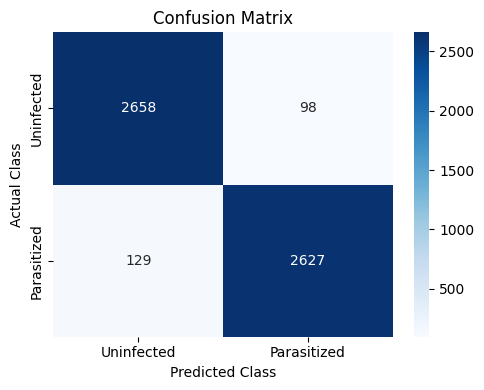


K-FOLD CROSS VALIDATION

RUNNING FOLD 1 / 5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


test time:  31.411s
accuracy:   0.960

              precision    recall  f1-score   support

  Uninfected      0.960     0.962     0.961      2797
 Parasitized      0.961     0.959     0.960      2715

    accuracy                          0.960      5512
   macro avg      0.960     0.960     0.960      5512
weighted avg      0.960     0.960     0.960      5512

Confusion Matrix Fold 1:
             Uninfected  Parasitized
Uninfected         2691          106
Parasitized         112         2603

RUNNING FOLD 2 / 5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


test time:  32.506s
accuracy:   0.960

              precision    recall  f1-score   support

  Uninfected      0.955     0.966     0.960      2735
 Parasitized      0.966     0.955     0.960      2777

    accuracy                          0.960      5512
   macro avg      0.960     0.960     0.960      5512
weighted avg      0.960     0.960     0.960      5512

Confusion Matrix Fold 2:
             Uninfected  Parasitized
Uninfected         2641           94
Parasitized         125         2652

RUNNING FOLD 3 / 5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


test time:  32.261s
accuracy:   0.957

              precision    recall  f1-score   support

  Uninfected      0.955     0.959     0.957      2769
 Parasitized      0.959     0.954     0.957      2743

    accuracy                          0.957      5512
   macro avg      0.957     0.957     0.957      5512
weighted avg      0.957     0.957     0.957      5512

Confusion Matrix Fold 3:
             Uninfected  Parasitized
Uninfected         2656          113
Parasitized         125         2618

RUNNING FOLD 4 / 5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


test time:  32.104s
accuracy:   0.963

              precision    recall  f1-score   support

  Uninfected      0.953     0.974     0.964      2761
 Parasitized      0.974     0.952     0.963      2750

    accuracy                          0.963      5511
   macro avg      0.963     0.963     0.963      5511
weighted avg      0.963     0.963     0.963      5511

Confusion Matrix Fold 4:
             Uninfected  Parasitized
Uninfected         2690           71
Parasitized         132         2618

RUNNING FOLD 5 / 5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


test time:  32.308s
accuracy:   0.960

              precision    recall  f1-score   support

  Uninfected      0.951     0.968     0.959      2717
 Parasitized      0.969     0.951     0.960      2794

    accuracy                          0.960      5511
   macro avg      0.960     0.960     0.960      5511
weighted avg      0.960     0.960     0.960      5511

Confusion Matrix Fold 5:
             Uninfected  Parasitized
Uninfected         2631           86
Parasitized         137         2657

REKAPITULASI HASIL EVALUASI 5-FOLD CROSS VALIDATION
Akurasi Fold 1 : 0.960
Akurasi Fold 2 : 0.960
Akurasi Fold 3 : 0.957
Akurasi Fold 4 : 0.963
Akurasi Fold 5 : 0.960

Rata-Rata Akurasi: 0.960


In [8]:
#EVALUASI MODEL
print("EVALUASI MODEL")

columns = ['Uninfected', 'Parasitized']

# 1. Hitung waktu pengujian (test time)
t = time()
X_test_meta = sigmoid_average(cnn1, cnn2, cnn3, X_test)
y_pred_prob = mlp.predict(X_test_meta, verbose=0)

# 2. Konversi probabilitas ke label biner (0 atau 1) threshold 0.5
y_pred = (y_pred_prob >= 0.5).astype(int)

# 3. Tampilkan waktu pengujian
test_time = time() - t
print("test time:  %0.3fs" % test_time)

# 4. Tampilkan akurasi
score = accuracy_score(y_test, y_pred)
print("accuracy:   %0.3f\n" % score)

# 5. Tampilkan classification report
print(classification_report(y_test, y_pred, target_names=columns, digits=3))

# 6. Visualisasi confusion matrix heatmap
cm_meta = confusion_matrix(y_test, y_pred)
df_meta = DataFrame(cm_meta, index=columns, columns=columns)
plt.figure(figsize=(5, 4))
sns.heatmap(df_meta, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

# 7. K-Fold cross validation (k=5)
print("\nK-FOLD CROSS VALIDATION")

k = 5
kf = KFold(n_splits=k, shuffle=True, random_state=42)
fold_accuracies = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X, y), 1):
    print(f"\nRUNNING FOLD {fold} / {k}")

    X_tr, y_tr = X[train_idx], y[train_idx]
    X_va, y_va = X[val_idx], y[val_idx]

    # Reset bobot bersih per fold
    m1 = build_cnn_1((64, 64, 3))
    m2 = build_cnn_2((64, 64, 3))
    m3 = build_cnn_3((64, 64, 3))
    b_models = [m1, m2, m3]

    for m in b_models:
        m.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
        m.fit(
            X_tr, y_tr,
            epochs=10,
            batch_size=32,
            validation_data=(X_va, y_va),
            verbose=0
        )

    X_tr_m = sigmoid_average(m1, m2, m3, X_tr)

    t_fold = time()
    X_va_m = sigmoid_average(m1, m2, m3, X_va)

    mlp_kfold = build_mlp((64, 32))
    mlp_kfold.fit(
        X_tr_m, y_tr,
        epochs=10,
        batch_size=32,
        validation_data=(X_va_m, y_va),
        verbose=0
    )

    y_pred_p_fold = mlp_kfold.predict(X_va_m, verbose=0)
    t_time_fold = time() - t_fold

    y_p_fold = (y_pred_p_fold >= 0.5).astype(int)
    acc_fold = accuracy_score(y_va, y_p_fold)
    fold_accuracies.append(acc_fold)

    # Output per fold
    print("test time:  %0.3fs" % t_time_fold)
    print("accuracy:   %0.3f\n" % acc_fold)
    print(classification_report(y_va, y_p_fold, target_names=columns, digits=3))

    cm_f = confusion_matrix(y_va, y_p_fold)
    df_f = DataFrame(cm_f, index=columns, columns=columns)
    print(f"Confusion Matrix Fold {fold}:")
    print(df_f)

    # Clean memori GPU colab setiap akhir fold
    tf.keras.backend.clear_session()
    gc.collect()

#Rata-rata akurasi k-fold
mean_acc = np.mean(fold_accuracies)
print(f"\nREKAPITULASI HASIL EVALUASI {k}-FOLD CROSS VALIDATION")
for i, a in enumerate(fold_accuracies, 1):
    print(f"Akurasi Fold {i} : %0.3f" % a)
print("\nRata-Rata Akurasi: %0.3f" % mean_acc)